# 波動方程式：差分法の比較


In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Noto Sans CJK JP"

plt.rcParams.update({
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.direction": "in",
    "ytick.direction": "in",
})


1次元波動方程式
\[
\frac{\partial^2\phi}{\partial t^2}
=v^2\frac{\partial^2\phi}{\partial x^2}
\]
には、初期変位 \(\phi(0,x)\) と初期速度 \(\partial_t\phi(0,x)\) の両方が必要である。
\(\psi=\partial_t\phi\) とおくと
\[
\partial_t\phi=\psi,\qquad
\partial_t\psi=v^2\partial_x^2\phi.
\]

固定端では \(\phi(t,0)=\phi(t,L)=0\)（Dirichlet条件）、
自由端では \(\partial_x\phi=0\)（Neumann条件）とする。
固定端は変位の節、自由端は変位の腹に対応する。
ここでは固定端を扱い、\(\Delta x=a\)、\(\Delta t=h\)、
\(r=hv^2/a^2\) と表す。

### 時間更新
FTCS法は両式を前進差分する。
\[
\phi^{n+1}=\phi^n+h\psi^n,\qquad
\psi^{n+1}=\psi^n+rL\phi^n.
\]
陰解法は両式を後退差分する。
\[
\phi^{n+1}=\phi^n+h\psi^{n+1},\qquad
\psi^{n+1}=\psi^n+rL\phi^{n+1}.
\]
\(L\phi_k=\phi_{k+1}-2\phi_k+\phi_{k-1}\) は2階差分である。


Crank--Nicolson法では、2式の右辺を前時刻と次時刻で平均する。
\[
\phi^{n+1}=\phi^n+\frac{h}{2}(\psi^{n+1}+\psi^n),
\qquad
\psi^{n+1}=\psi^n+\frac{r}{2}L(\phi^{n+1}+\phi^n).
\]
第1式を第2式に代入し、両辺を4倍すると
\[
(4I-rhL)\psi^{n+1}=(4I+rhL)\psi^n+4rL\phi^n.
\]
内部点では三重対角方程式
\[
-rh\psi^{n+1}_{k-1}+(4+2rh)\psi^{n+1}_k-rh\psi^{n+1}_{k+1}
=4\psi^n_k+4rL\phi^n_k+rhL\psi^n_k
\]
を解き、\(\phi^{n+1}\)を時間平均の式で更新する。


In [2]:
from scipy.linalg import solve_banded

def second_difference(u):
    return u[2:] - 2 * u[1:-1] + u[:-2]

def linsolve_tridiagonal(diagonal, off, rhs):
    ab = np.zeros((3, len(diagonal)), dtype=np.result_type(diagonal, rhs))
    ab[0, 1:] = off
    ab[1] = diagonal
    ab[2, :-1] = off
    return solve_banded((1, 1), ab, rhs)


In [3]:
# Crank-Nicolson法の1時間ステップ
def wave_crank_nicolson_iteration(phi, psi, h, r):
    n = len(phi) - 2
    phinew, psinew = phi.copy(), psi.copy()
    diagonal = np.full(n, 4 + 2 * r * h)
    off = np.full(n - 1, -r * h)
    rhs = 4 * psi[1:-1] + 4 * r * second_difference(phi)         + r * h * second_difference(psi)
    psinew[1:-1] = linsolve_tridiagonal(diagonal, off, rhs)
    phinew[1:-1] = phi[1:-1] + (h / 2) * (psinew[1:-1] + psi[1:-1])
    return phinew, psinew

def wave_crank_nicolson_solve(phi0, psi0, h, nsteps, a, v):
    phi, psi = phi0.copy(), psi0.copy()
    r = h * v**2 / a**2
    for _ in range(nsteps):
        phi, psi = wave_crank_nicolson_iteration(phi, psi, h, r)
    return phi, psi

def discrete_energy(phi, psi, a, v):
    kinetic = a * np.sum(psi[1:-1] ** 2) / 2
    elastic = v**2 * np.sum(np.diff(phi) ** 2) / (2 * a)
    return kinetic + elastic


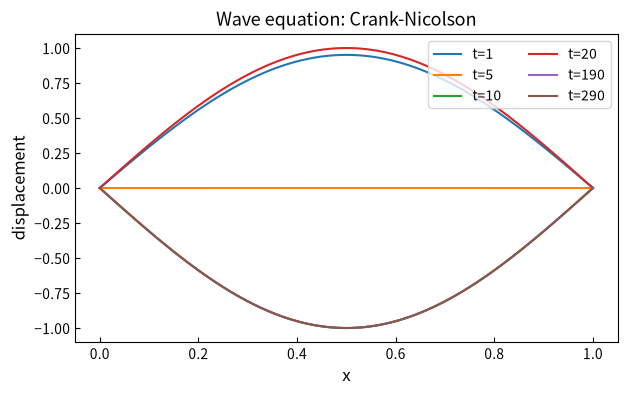

CPU times: user 350 ms, sys: 12 ms, total: 362 ms
Wall time: 362 ms


In [4]:
%%time

L = 1.0
N = 100
a = L / N
v = 0.1
h = 0.05
r = h * v**2 / a**2
x = np.linspace(0, L, N + 1)
phi = np.sin(np.pi * x / L)
phi[[0, -1]] = 0.0
psi = np.zeros_like(x)

times = [1, 5, 10, 20, 190, 290]
profiles = []
current_time = 0.0
for target in times:
    nsteps = round((target - current_time) / h)
    phi, psi = wave_crank_nicolson_solve(phi, psi, h, nsteps, a, v)
    profiles.append(phi.copy())
    current_time += nsteps * h

assert np.allclose(phi[[0, -1]], 0.0)
plt.figure(figsize=(7, 4))
plt.title("Wave equation: Crank-Nicolson")
plt.xlabel("x")
plt.ylabel("displacement")
for t, profile in zip(times, profiles):
    plt.plot(x, profile, label=f"t={t}")
plt.legend(ncol=2)
plt.show()


## アニメーション：固定端の基本振動


In [5]:
from matplotlib.animation import FuncAnimation

L = 1.0
N = 100
a = L / N
v = 0.1
h = 0.01
r = h * v**2 / a**2
x = np.linspace(0, L, N + 1)
phi = np.sin(np.pi * x / L)
phi[[0, -1]] = 0.0
psi = np.zeros_like(x)

history = [phi.copy()]
steps = 2000
for step in range(1, steps + 1):
    phi, psi = wave_crank_nicolson_iteration(phi, psi, h, r)
    if step % 25 == 0:
        history.append(phi.copy())

fig, ax = plt.subplots(figsize=(7, 4))
line, = ax.plot(x, history[0])
ax.set(xlim=(0, L), ylim=(-1.1, 1.1), xlabel="x", ylabel="displacement")

def update(frame):
    line.set_ydata(history[frame])
    ax.set_title(f"Crank-Nicolson: t={frame * 25 * h:.2f}")
    return (line,)

ani = FuncAnimation(fig, update, frames=len(history), interval=70, blit=True)
ani.save("wave_equation_1D_CrankNicolson.gif", writer="pillow", fps=12)
plt.close(fig)


# 安定性の見方

同じ初期値でも、時間更新式ごとに離散エネルギーの変化が異なる。
次の比較では格子スケールに近いモードを使い、差が有限値のうちに見えるようにする。


### FTCS法
\[
\phi^{n+1}_k=\phi^n_k+h\psi^n_k,\qquad
\psi^{n+1}_k=\psi^n_k+r(\phi^n_{k+1}-2\phi^n_k+\phi^n_{k-1}).
\]
空間差分の固有モードは調和振動子になる。前進Euler法の増幅率は
\(\sqrt{1+(h\Omega)^2}>1\)なので、非零の時間刻みではモードが増幅する。


In [6]:
# FTCS法
def wave_ftcs_iteration(phi, psi, h, r):
    phinew, psinew = phi.copy(), psi.copy()
    phinew[1:-1] = phi[1:-1] + h * psi[1:-1]
    psinew[1:-1] = psi[1:-1] + r * second_difference(phi)
    return phinew, psinew

def wave_ftcs_solve(phi0, psi0, h, nsteps, a, v):
    phi, psi = phi0.copy(), psi0.copy()
    r = h * v**2 / a**2
    for _ in range(nsteps):
        phi, psi = wave_ftcs_iteration(phi, psi, h, r)
    return phi, psi


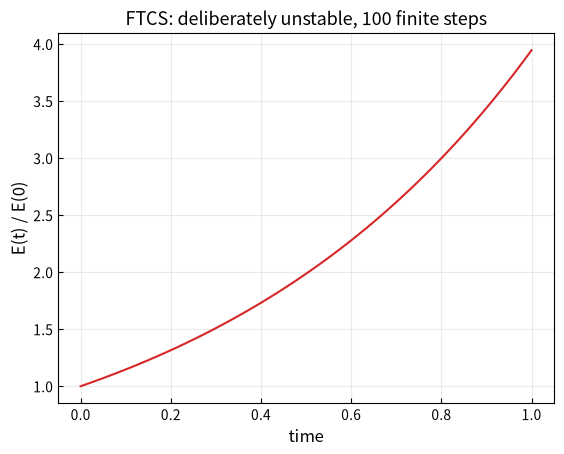

CPU times: user 54.1 ms, sys: 2.09 ms, total: 56.2 ms
Wall time: 55.5 ms


In [7]:
%%time

L = 1.0
N = 100
a = L / N
v = 0.1
h = 0.01
x = np.linspace(0, L, N + 1)
mode = 40
phi0 = np.sin(mode * np.pi * x / L)
phi0[[0, -1]] = 0.0
psi0 = np.zeros_like(x)
r = h * v**2 / a**2
energy0 = discrete_energy(phi0, psi0, a, v)
phi, psi = phi0.copy(), psi0.copy()
ratios = [1.0]
for _ in range(100):
    phi, psi = wave_ftcs_iteration(phi, psi, h, r)
    ratios.append(discrete_energy(phi, psi, a, v) / energy0)

assert np.isfinite(ratios).all()
assert ratios[-1] > 2
plt.figure()
plt.plot(np.arange(101) * h, ratios, color="tab:red")
plt.xlabel("time")
plt.ylabel("E(t) / E(0)")
plt.title("FTCS: deliberately unstable, 100 finite steps")
plt.grid(alpha=0.25)
plt.show()


### 陰解法
\[
\phi^{n+1}=\phi^n+h\psi^{n+1},\qquad
\psi^{n+1}=\psi^n+rL\phi^{n+1}.
\]
\(\phi^{n+1}\)を消去すると
\[
(I-rhL)\psi^{n+1}=\psi^n+rL\phi^n.
\]
この方法は安定だが、振動モードの振幅を時間とともに減衰させる。


In [8]:
# 陰解法（後退Euler法）
def wave_implicit_iteration(phi, psi, h, r):
    n = len(phi) - 2
    phinew, psinew = phi.copy(), psi.copy()
    diagonal = np.full(n, 1 + 2 * r * h)
    off = np.full(n - 1, -r * h)
    rhs = psi[1:-1] + r * second_difference(phi)
    psinew[1:-1] = linsolve_tridiagonal(diagonal, off, rhs)
    phinew[1:-1] = phi[1:-1] + h * psinew[1:-1]
    return phinew, psinew

def wave_implicit_solve(phi0, psi0, h, nsteps, a, v):
    phi, psi = phi0.copy(), psi0.copy()
    r = h * v**2 / a**2
    for _ in range(nsteps):
        phi, psi = wave_implicit_iteration(phi, psi, h, r)
    return phi, psi


In [9]:
%%time

L = 1.0
N = 100
a = L / N
v = 0.1
h = 0.01
x = np.linspace(0, L, N + 1)
phi0 = np.sin(40 * np.pi * x / L)
phi0[[0, -1]] = 0.0
psi0 = np.zeros_like(x)
energy0 = discrete_energy(phi0, psi0, a, v)
phi, psi = wave_implicit_solve(phi0, psi0, h, 100, a, v)
energy_ratio = discrete_energy(phi, psi, a, v) / energy0
print("E(1) / E(0) =", energy_ratio)
assert 0 < energy_ratio < 1


E(1) / E(0) = 0.2534714878062846
CPU times: user 2.43 ms, sys: 0 ns, total: 2.43 ms
Wall time: 2.41 ms


## 時間更新法を同じ初期値で比較する

FTCS法、陰解法、Crank--Nicolson法を同じ格子と初期モードで100ステップ進める。
有限値を保ったまま、増幅・減衰・保存を確認する。


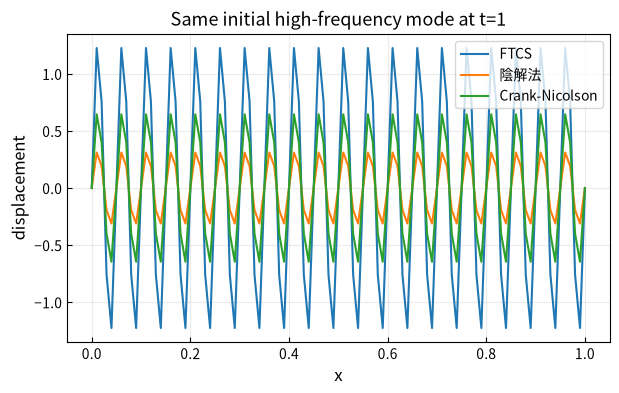

{'FTCS': np.float64(3.9452169104094885), '陰解法': np.float64(0.2534714878062846), 'Crank-Nicolson': np.float64(1.000000000000021)}


In [10]:
L = 1.0
N = 100
a = L / N
v = 0.1
h = 0.01
r = h * v**2 / a**2
x = np.linspace(0, L, N + 1)
phi0 = np.sin(40 * np.pi * x / L)
phi0[[0, -1]] = 0.0
psi0 = np.zeros_like(x)
energy0 = discrete_energy(phi0, psi0, a, v)
methods = {
    "FTCS": wave_ftcs_iteration,
    "陰解法": wave_implicit_iteration,
    "Crank-Nicolson": wave_crank_nicolson_iteration,
}
fig, ax = plt.subplots(figsize=(7, 4))
final_energy = {}
for name, iteration in methods.items():
    phi, psi = phi0.copy(), psi0.copy()
    for _ in range(100):
        phi, psi = iteration(phi, psi, h, r)
    assert np.isfinite(phi).all() and np.isfinite(psi).all()
    final_energy[name] = discrete_energy(phi, psi, a, v) / energy0
    ax.plot(x, phi, label=name)
ax.set(xlabel="x", ylabel="displacement", title="Same initial high-frequency mode at t=1")
ax.legend()
ax.grid(alpha=0.25)
plt.show()
print(final_energy)
assert final_energy["FTCS"] > 2
assert final_energy["陰解法"] < 1
assert np.isclose(final_energy["Crank-Nicolson"], 1, rtol=1e-10, atol=1e-10)
